# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


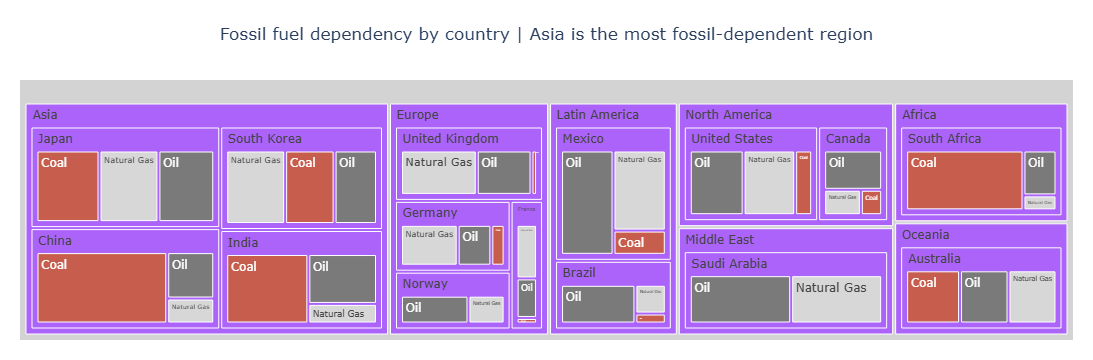

In [3]:
# Task 1
# Task 1
df_fossil = df.loc[df['Source_Type'] == 'Fossil', ['Region', 'Country', 'Source', 'TWh']].copy()

fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map={
        'Coal': '#c65d4d',
        'Oil': '#7a7a7a',
        'Natural Gas': '#d7d7d7'
    },
    title='Fossil fuel dependency by country | Asia is the most fossil-dependent region'
)

fig1.update_traces(
    root_color='lightgrey',
    marker=dict(line=dict(color='white', width=1))
)
fig1.update_layout(
    margin=dict(t=80, l=20, r=20, b=20),
    title_x=0.5
)
fig1.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

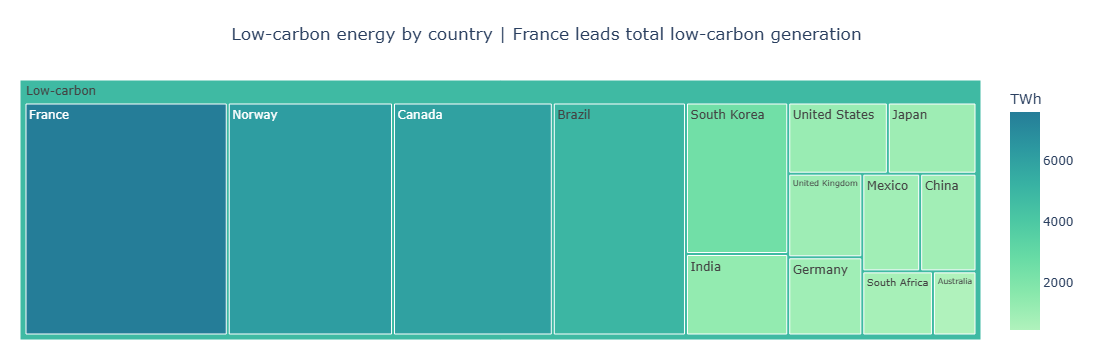

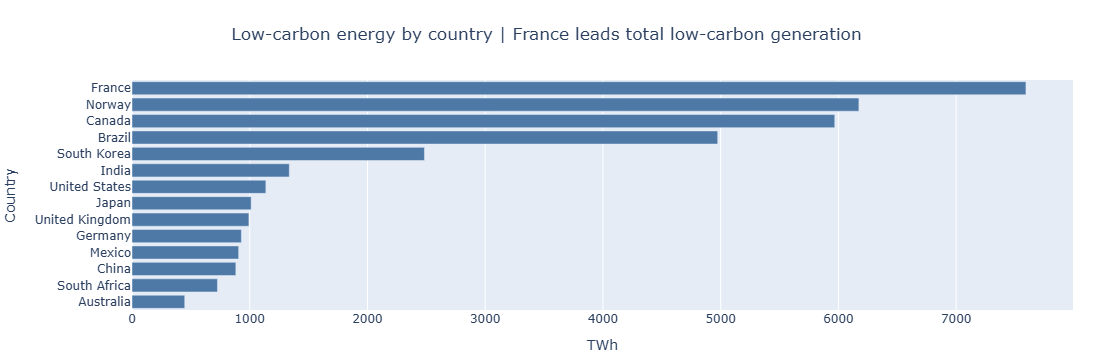

In [4]:
# Task 2 — charts
# YOUR CODE HERE

low_carbon = df.loc[df['Source_Type'] == 'Low-carbon'].copy()

# Aggregate by country
low_carbon_country = (
    low_carbon.groupby('Country', as_index=False)['TWh']
    .sum()
    .sort_values('TWh', ascending=False)
)

# Treemap: dummy root node labelled 'Low-carbon'
low_carbon_country['All'] = 'Low-carbon'

fig2_treemap = px.treemap(
    low_carbon_country,
    path=['All', 'Country'],
    values='TWh',
    color='TWh',
    color_continuous_scale='Tealgrn',
    title='Low-carbon energy by country | France leads total low-carbon generation'
)
fig2_treemap.update_traces(
    root_color='lightgrey',
    marker=dict(line=dict(color='white', width=1))
)
fig2_treemap.update_layout(
    margin=dict(t=80, l=20, r=20, b=20),
    title_x=0.5
)
fig2_treemap.show()

# Bar chart: sorted by TWh, horizontal
fig2_bar = px.bar(
    low_carbon_country,
    x='TWh',
    y='Country',
    orientation='h',
    color_discrete_sequence=['#4e79a7'] * len(low_carbon_country),
    title='Low-carbon energy by country | France leads total low-carbon generation'
)

fig2_bar.update_layout(
    yaxis={'categoryorder':'total ascending'},
    margin=dict(t=80, l=10, r=20, b=20),
    title_x=0.5
)
fig2_bar.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*I think the horizontal bar chart is easier to understand because you can quickly see which countries use the most and least energy. The bars are arranged from highest to lowest, so it's easy to compare the countries and see their rankings.*

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

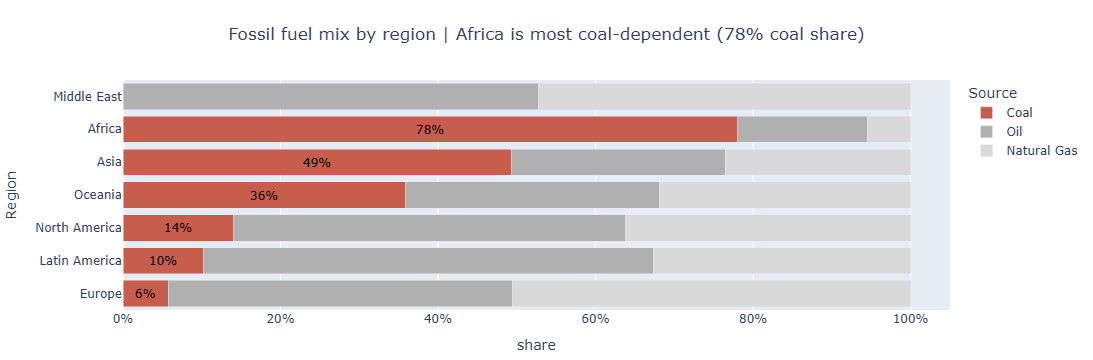

In [6]:
# Task 3
# YOUR CODE HERE
# Task 3
# YOUR CODE HERE
# Task 3

# Reuse fossil data from Task 1
df_fossil = df.loc[df['Source_Type'] == 'Fossil', ['Region', 'Country', 'Source', 'TWh']].copy()

# Aggregate by Region x Source
df_region_source = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()

# Add region totals and percentage shares
region_total = (
    df_fossil.groupby('Region', as_index=False)['TWh']
    .sum()
    .rename(columns={'TWh': 'Region_total'})
)
df_region_source = df_region_source.merge(region_total, on='Region')
df_region_source['share'] = df_region_source['TWh'] / df_region_source['Region_total']

# Sort regions by coal share, highest at top
coal_order = (
    df_region_source.loc[df_region_source['Source'] == 'Coal']
    .sort_values('share', ascending=False)['Region']
    .tolist()
)

# Include all unique regions in the category order
region_order = df_region_source['Region'].dropna().unique().tolist()

df_region_source['Region'] = pd.Categorical(
    df_region_source['Region'],
    categories=region_order,
    ordered=True
)

df_region_source = df_region_source.sort_values('Region')
fig3 = px.bar(
    df_region_source,
    x='share',
    y='Region',
    color='Source',
    orientation='h',
    barmode='stack',
    category_orders={'Region': coal_order, 'Source': ['Coal', 'Oil', 'Natural Gas']},
    color_discrete_map={
        'Coal': '#c65d4d',
        'Oil': '#b0b0b0',
        'Natural Gas': '#d9d9d9'
    },
    title='Fossil fuel mix by region | Africa is most coal-dependent (78% coal share)'
)

fig3.update_xaxes(tickformat='.0%', range=[0, 1.05])
fig3.update_layout(
    margin=dict(t=80, l=10, r=30, b=20),
    title_x=0.5
)

# Coal labels only
for row in df_region_source[df_region_source['Source'] == 'Coal'].itertuples():
    fig3.add_annotation(
        x=row.share / 2,
        y=row.Region,
        text=f'{row.share * 100:.0f}%',
        showarrow=False,
        font=dict(size=12, color='black'),
        xanchor='center',
        yanchor='middle'
    )

fig3.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*The treemap makes it easier to see how much each energy source contributes to the total, while the stacked bar chart makes it easier to compare the coal, oil and natural gas shares across regions. The treemap shows the overall amounts, but the bar chart clearly shows which regions depend more on coal.*